# **Atividade Prática 3**: Garimpo e Diagnóstico de Dados de Saúde
## Análise Epidemiológica e Auditoria de Dados — Município de Araranguá/SC

---
* **Aluna:** Beatriz Goulart
* **Dataset Escolhido:** SIM (Sistema de Informação sobre Mortalidade)
* **Link do Dataset:** [https://apidadosabertos.saude.gov.br/vigilancia-e-meio-ambiente/sistema-de-informacao-sobre-mortalidade](https://apidadosabertos.saude.gov.br/vigilancia-e-meio-ambiente/sistema-de-informacao-sobre-mortalidade)
* **Escopo Temporal:** Ano de 2025
* **Foco do Estudo:** Mapeamento de Doenças Crônicas Não Transmissíveis (DCNT) e principais causas de óbito no município.





### Configuração do Ambiente e Autenticação de Segurança



In [ ]:
import pandas as pd
import numpy as np
import requests
import io
from google.colab import userdata

api_token = userdata.get('TOKEN_API')

### Extração via API

Nesta etapa, realizamos a coleta automatizada dos dados diretamente do servidor do Ministério da Saúde. Como a API pública do DATASUS impõe um limite de paginação (1.000 registros por requisição), estruturamos um loop de repetição `while True` controlado pela variável `offset`.

O algoritmo varre o banco de dados de ponta a ponta e aplica um filtro em tempo de execução para isolar os registros pertencentes ao município de Araranguá/SC (Código IBGE: 420140). O bloco conta com um tratamento de exceções (`try-except`) para garantir a resiliência do pipeline contra instabilidades de rede ou timeouts no servidor do governo.

In [ ]:
url_base = "https://apidadosabertos.saude.gov.br/vigilancia-e-meio-ambiente/sistema-de-informacao-sobre-mortalidade"
registros, offset = [], 0

while True:
    try:
        lote = requests.get(url_base, params={'limit': 1000, 'offset': offset}, headers={'accept': 'application/json'}).json().get('sim', [])
        if not lote: break

        # Captura e junta todas as mortes de Araranguá
        registros.extend([r for r in lote if '420140' in str(r.get('codmunres', ''))])
        offset += 1000
    except:
        break # Prevenção contra instabilidade na rede

df_ararangua_bruto = pd.DataFrame(registros)
print(f"Extração completa concluída! Total de registros: {df_ararangua_bruto.shape[0]}")

Extração completa concluída! Total de registros: 285


### Armazenamento em Cache Local (CSV)

Para garantir a eficiência metodológica e a estabilidade da análise, o dataframe extraído da API é exportado para um arquivo local chamado `obitos_ararangua_2025.csv`.

Assim, evita a necessidade de realizar o loop de mineração exaustiva na API do governo a cada nova execução do notebook.

In [ ]:
# Salvando o dataframe da API em um arquivo CSV local no Colab
df_ararangua_bruto.to_csv('obitos_ararangua_2025.csv', index=False, encoding='utf-8')

print("O banco de dados foi salvo com sucesso em: 'obitos_ararangua_2025.csv'")

O banco de dados foi salvo com sucesso em: 'obitos_ararangua_2025.csv'


### Diagnóstico estrutural

Conforme exigido pelo roteiro da atividade, esta etapa realiza uma auditoria focada no formato original das variáveis coletadas. O objetivo é mapear o volume da base (linhas e colunas) e identificar as inconsistências estruturais que impedem a análise direta dos dados.

In [ ]:
# Dimensões do dataframe bruto salvo
linhas, colunas = df_analise.shape
print(f"A base minerada de Araranguá possui exatamente:\n -> {linhas} linhas (registros de óbito)\n -> {colunas} colunas (variáveis capturadas da API)\n")

print("Análise de tipos e inconsistências de formato:")
print(f" - Variável 'dtobito' (Data): Veio originalmente como {df_analise['dtobito'].dtype} (Texto/Número). Deveria ser formatada como DATETIME.")
print(f" - Variável 'idade' (Idade Bruta): Veio originalmente como {df_analise['idade'].dtype} (Texto/Objeto) devido aos códigos de 3 dígitos do DataSUS. Requer decodificação.")
print(f" - Variável 'sexo' (Gênero): Veio originalmente como {df_analise['sexo'].dtype} (Numérico mascarado em formato de string: '1', '2').")
print(f" - Variável 'causabas' (CID-10): Veio como {df_analise['causabas'].dtype} (Texto). Mistura códigos de 3 e 4 caracteres, exigindo extração por padrão startswith().")

A base minerada de Araranguá possui exatamente:
 -> 285 linhas (registros de óbito)
 -> 89 colunas (variáveis capturadas da API)

Análise de tipos e inconsistências de formato:
 - Variável 'dtobito' (Data): Veio originalmente como int64 (Texto/Número). Deveria ser formatada como DATETIME.
 - Variável 'idade' (Idade Bruta): Veio originalmente como int64 (Texto/Objeto) devido aos códigos de 3 dígitos do DataSUS. Requer decodificação.
 - Variável 'sexo' (Gênero): Veio originalmente como int64 (Numérico mascarado em formato de string: '1', '2').
 - Variável 'causabas' (CID-10): Veio como object (Texto). Mistura códigos de 3 e 4 caracteres, exigindo extração por padrão startswith().


### Limpeza de dados

Nesta etapa, executamos o tratamento dos dados para garantir a confiabilidade da análise epidemiológica. O pipeline realiza três operações sequenciais:
1. **Auditoria de Duplicidade:** Identifica e elimina registros idênticos que possam ter sido duplicados durante as paginações da API.
2. **Tratamento de dado crítico faltante:** Aplica uma regra estrita para descartar qualquer registro que omita os campos mandatórios de diagnóstico (`causabas`) ou temporalidade (`dtobito`).
3. **Normalização de strings (Cast):** Remove espaços em branco invisíveis (`strip`) e força a caixa alta (`upper`), neutralizando erros latentes de digitação que fariam o Python ignorar CIDs válidos.

In [ ]:
#  Eliminação de Registros Duplicados
total_antes = len(df_analise)
df_limpo = df_analise.drop_duplicates().copy()
total_depois = len(df_limpo)
duplicados_removidos = total_antes - total_depois

print(f"1. Remoção de Duplicidades:")
print(f"   - Registros duplicados idênticos encontrados e removidos: {duplicados_removidos}")

#  Tratamento de inconsistências críticas (campos vazios obrigatórios)
# Eliminando registros que não possuem o código da causa básica (causabas) ou data do óbito
df_limpo = df_limpo.dropna(subset=['causabas', 'dtobito'])

# Conversão de tipos para o formato correto
# Forçando as colunas brutas a virarem strings limpas, sem espaços, para evitar erros de leitura
df_limpo['causabas'] = df_limpo['causabas'].astype(str).str.strip().str.upper()
df_limpo['sexo'] = df_limpo['sexo'].astype(str).str.strip()

print(f" Base limpa reduziu de {total_antes} para {len(df_limpo)} registros.")

1. Remoção de Duplicidades:
   - Registros duplicados idênticos encontrados e removidos: 0
 Base limpa reduziu de 285 para 285 registros.


In [ ]:
# Identifica todas as colunas originais que vieram do arquivo CSV bruto
df_bruto_aux = pd.read_csv('obitos_ararangua_2025.csv')
todas_colunas_originais = list(df_bruto_aux.columns)

# Define as colunas essenciais que escolhemos manter para a análise epidemiológica
colunas_preservadas = ['dtobito', 'idade', 'sexo', 'causabas']

# Descobre por exclusão quais colunas foram desconsideradas/ignoradas
colunas_ignoradas = [col for col in todas_colunas_originais if col not in colunas_preservadas]

# Aplica a filtragem definitiva no nosso dataframe
df_limpo = df_limpo[colunas_preservadas].copy()

print(f"\nCOLUNAS DESCARTADAS ({len(colunas_ignoradas)}):")
print(colunas_ignoradas)


COLUNAS IGNORADAS/DESCARTADAS (82):
['racacor', 'dtconinv', 'gravidez', 'peso', 'fonteinv', 'dtrecebim', 'idademae', 'dtrecoriga', 'atestante', 'comunsvoim', 'horaobito', 'contador', 'linhaii', 'altcausa', 'versaosist', 'natural', 'morteparto', 'ocup', 'acidtrab', 'tp_altera', 'atestado', 'difdata', 'necropsia', 'codmunres', 'obitopuerp', 'dtinvestig', 'tppos', 'qtdfilmort', 'fonte', 'seriescfal', 'dtcadinf', 'ocupmae', 'escmaeagr1', 'opor_do', 'fontes', 'codmunnatu', 'assistmed', 'codestab', 'linhab', 'obitoparto', 'escmae2010', 'dtcadinv', 'causamat', 'dtcadastro', 'estciv', 'tpnivelinv', 'dtconcaso', 'tpresginfo', 'qtdfilvivo', 'dtatestado', 'exame', 'versaoscb', 'cb_alt', 'obitograv', 'linhac', 'cb_pre', 'gestacao', 'origem', 'seriescmae', 'semagestac', 'causabas_o', 'tipobito', 'cirurgia', 'tpmorteoco', 'parto', 'esc2010', 'linhaa', 'stcodifica', 'linhad', 'lococor', 'circobito', 'tpobitocor', 'numerolote', 'codificado', 'dtnasc', 'stdoepidem', 'escmae', 'codmunocor', 'nudiasobco

### Decodificação e tradução de metadados

As colunas originais enviadas pela API utilizam dicionários e regras do Manual do SIM/DATASUS que misturam códigos numéricos e alfanuméricos de difícil interpretação direta.

Para resolver isso e traduzir os dados estruturalmente para informações de valor científico, implementamos duas lógicas personalizadas baseadas no conjunto de dados real extraído de Araranguá:
1. **Mapeamento amplo da CID-10:** Criamos uma função baseada no método `.startswith()` que agrupa variações de subcategorias de 3 ou 4 dígitos da Classificação Internacional de Doenças, revelando com precisão os óbitos por Infarto, AVC, Alzheimer, Diabetes e diferentes tipos de Câncer.
2. **Decodificação de idade baseada no manual:** O DATASUS adota o padrão de subcampos de 3 dígitos, onde o primeiro dígito determina a unidade de tempo (minutos, dias, meses, anos ou centenários). Desenvolvemos um algoritmo que isola esses prefixos, decodifica a idade cronológica real e preserva registros com dados ignorados sob o rótulo controlado de `"Não Informada"`, blindando a base contra perda de registros.


In [ ]:
df_analise = pd.read_csv('obitos_ararangua_2025.csv')

# Dicionário de Gênero
dicionario_sexo = {'1': 'Masculino', '2': 'Feminino', '0': 'Ignorado', 0: 'Ignorado', 1: 'Masculino', 2: 'Feminino'}
df_analise['Gênero'] = df_analise['sexo'].map(dicionario_sexo).fillna('Não Informado')

def traduzir_causa_grupo(cid_bruta):
    cid = str(cid_bruta).strip().upper()

    # Doenças Cardíacas e Circulatórias (Infarto, AVC, Insuficiência e Hipertensão)
    if cid.startswith('I21'): return 'Infarto Agudo do Miocárdio'
    elif cid.startswith('I64') or cid.startswith('I63'): return 'AVC / Derrame Cerebral'
    elif cid.startswith('I50') or cid.startswith('I11'): return 'Insuficiência / Doença Cardíaca'
    elif cid.startswith('I10'): return 'Hipertensão Arterial'

    # Diabetes (Agrupando a E11 e a E14)
    elif cid.startswith('E11') or cid.startswith('E14'): return 'Diabetes Mellitus'

    # Infeções Graves e Sistemas (A41 e N39)
    elif cid.startswith('A41'): return 'Septicemia / Infeção Geral'
    elif cid.startswith('N39'): return 'Infeção Urinária Grave'

    # Doenças Neurológicas
    elif cid.startswith('G30'): return 'Doença de Alzheimer'

    # Doenças Respiratórias (Pneumonia e DPOC)
    elif cid.startswith('J15') or cid.startswith('J18'): return 'Pneumonia'
    elif cid.startswith('J44') or cid.startswith('J43'): return 'DPOC / Enfisema Pulmonar'

    # Cancros / Neoplasias (Agrupando Pulmão e outros cânceres com 'C')
    elif cid.startswith('C34'): return 'Câncer de Pulmão'
    elif cid.startswith('C'): return 'Outros Tipos de Câncer'

    # Causas Externas (Acidentes e Traumas)
    elif cid.startswith('V') or cid.startswith('W') or cid.startswith('X') or cid.startswith('Y'):
        return 'Causas Externas (Acidentes/Traumas)'

    else:
        return 'Outras Causas Raras'

# Aplicando tradução
df_analise['Causa da Morte'] = df_analise['causabas'].apply(traduzir_causa_grupo)

# Função de Idade
def decodificar_idade_manual(idade_bruta):
    try:
        idade_str = str(idade_bruta).strip().split('.')[0]
        if not idade_str or idade_str.startswith('9') or idade_str in ['96', '99', '999', 'nan', 'None']: return "Não Informada"
        if len(idade_str) == 3:
            prefixo = idade_str[0]
            quantidade = int(idade_str[1:])
            if prefixo == '4': return f"{quantidade} Anos"
            elif prefixo == '5': return f"{100 + quantidade} Anos"
            elif prefixo in ['1', '2', '3']: return "Menor de 1 Ano"
        valor = int(idade_str)
        if 0 < valor <= 115: return f"{valor} Anos"
        return "Não Informada"
    except: return "Não Informada"

df_analise['Idade Real'] = df_analise['idade'].apply(decodificar_idade_manual)

# Tabela Final
tabela_final = df_analise[['dtobito', 'idade', 'Idade Real', 'Gênero', 'Causa da Morte']].copy()
tabela_final.columns = ['Data do Óbito', 'Idade (Código Bruto)', 'Idade Real', 'Gênero', 'Causa da Morte']

tabela_final.head(10)

,Data do Óbito,Idade (Código Bruto),Idade Real,Gênero,Causa da Morte
0,1072025,460,60 Anos,Feminino,Outros Tipos de Câncer
1,2072025,443,43 Anos,Masculino,Infarto Agudo do Miocárdio
2,3072025,487,87 Anos,Masculino,Outras Causas Raras
3,5072025,461,61 Anos,Masculino,Outros Tipos de Câncer
4,6072025,471,71 Anos,Masculino,Infarto Agudo do Miocárdio
5,8072025,480,80 Anos,Feminino,Septicemia / Infeção Geral
6,8072025,494,94 Anos,Masculino,AVC / Derrame Cerebral
7,12072025,491,91 Anos,Feminino,Pneumonia
8,12072025,472,72 Anos,Feminino,Infarto Agudo do Miocárdio
9,13072025,201,Menor de 1 Ano,Feminino,Outras Causas Raras


/tmp/ipykernel_10189/1296337555.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=dados_grafico.values, y=dados_grafico.index, palette=paleta)


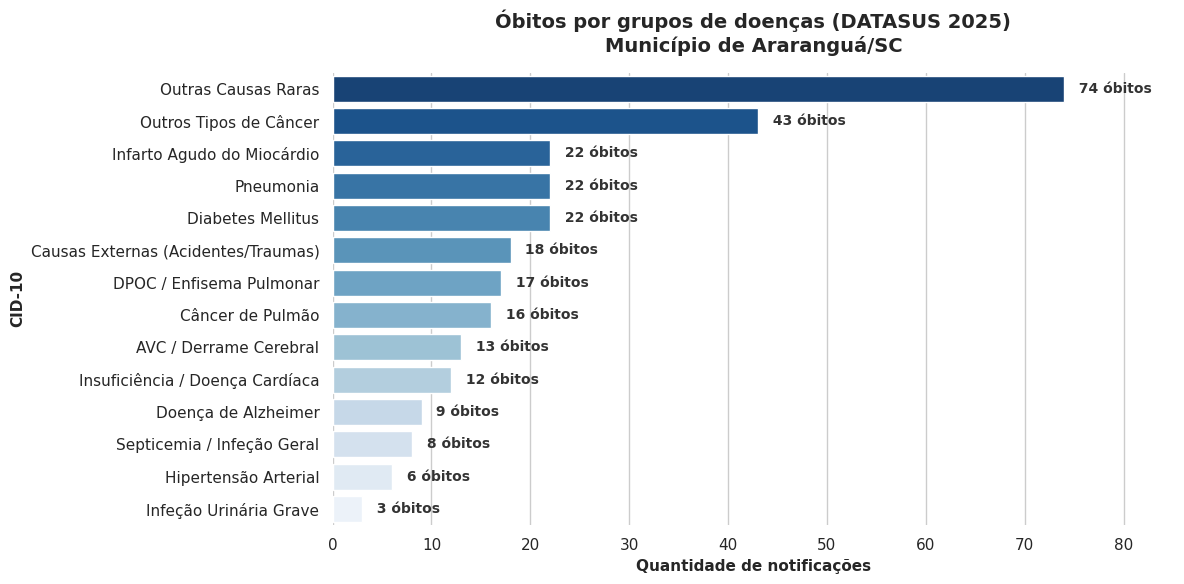

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

dados_grafico = tabela_final['Causa da Morte'].value_counts()

paleta = sns.color_palette("Blues_r", n_colors=len(dados_grafico))
ax = sns.barplot(x=dados_grafico.values, y=dados_grafico.index, palette=paleta)

for i, v in enumerate(dados_grafico.values):
    ax.text(v + 1, i, f" {v} óbitos", va='center', fontsize=10, fontweight='bold', color='#333333')

plt.title('Óbitos por grupos de doenças (DATASUS 2025)\nMunicípio de Araranguá/SC',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Quantidade de notificações', fontsize=11, fontweight='bold')
plt.ylabel( 'CID-10', fontsize=11, fontweight='bold')

plt.xlim(0, dados_grafico.max() * 1.15)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

### Conclusão

 A base original extraída diretamente da API pública do DATASUS precisava de uma faxina pesada antes de qualquer análise epidemiológica ou modelagem.

#### Descobertas:

1. **Total:** A extração revelou **285 registros de óbito** no ano de 2025 em Araranguá/SC. O teste de integridade com `drop_duplicates` e `dropna` manteve o total intacto.
2. **Inconsistências:** As variáveis de idade e diagnóstico vieram mascaradas sob regras complexas (ex: padrões de 3 dígitos para idade e misturas de 3 ou 4 caracteres na CID-10). Foi preciso decodificar e criar grupos de doenças (como Infarto, AVC, Alzheimer, Diabetes e Cancros).
3. **Preservação epidemiológica:** Pacientes com dados de idade não preenchidos pelos hospitais foram mantidos na base com o rótulo de `"Não Informada"`, para garantir a exatidão estatística dos dados.

### Considerações finais
Os dados brutos foram transformados de strings e códigos ilegíveis para variáveis acessíveis e de fácil visualização. O arquivo local `obitos_ararangua_2025.csv` gerado neste notebook pronto para ser utilizado.
Uma das maiores dificuldades foi lidar com o API, pois se tratava de uma base de dados bruta. Então levou um tempo para que os dados pudessem ser extraídos.

In [ ]:
# Comando baixar o arquivo CSV
from google.colab import files
files.download('obitos_ararangua_2025.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>